# Online News Popularity: Machine Learning

**Prediction question:** Can an article's content, category, sentiment, and
publication-day characteristics predict whether it will receive at least
**2,800 shares**?

This shared notebook implements **logistic regression and histogram gradient
boosting**. Random Forest remains an empty placeholder. The final comparison
of three different model types is still pending.

## Setup and Data

Keep `OnlineNewsPopularity.csv` beside this notebook and run the cells in order.
Install the project's `requirements.txt` in your Python environment first;
the optional cell below is an alternative for installing just the ML libraries.

In [ ]:
# Uncomment and run once if needed.
# %pip install pandas numpy matplotlib scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    make_scorer, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)

df = pd.read_csv("OnlineNewsPopularity.csv")
df.columns = df.columns.str.strip()
print(f"Dataset: {df.shape[0]:,} articles and {df.shape[1]} columns")
print(f"Missing values: {df.isna().sum().sum():,}")
print(f"Duplicate article URLs: {df['url'].duplicated().sum():,}")

Dataset: 39,644 articles and 61 columns
Missing values: 0
Duplicate article URLs: 0


## Define the Target and Predictors

- **Popular (1):** at least 2,800 shares; **not popular (0):** fewer than 2,800.
- The cutoff comes from the earlier EDA's approximate upper quartile. We keep it
  fixed here rather than calculating a new cutoff from the test set. Around one
  quarter of articles are popular, so the classes are not balanced.
- The earlier model used article length alone. This version uses 19 original
  features: article/title length, links, media counts, average token length,
  keyword count, sentiment, six category flags, and the weekend flag.
- URL is an identifier, and `timedelta` measures article age after publication.
  Both are excluded. Keyword share statistics and self-reference share counts
  are also excluded because their availability at prediction time is uncertain.
- `shares` creates the target but is never an input. EDA-derived columns such as
  `log_shares` and `is_popular` are not included in the predictor list.

In [3]:
POPULAR_CUTOFF = 2800
RANDOM_STATE = 13

feature_columns = [
    "n_tokens_title", "n_tokens_content", "num_hrefs", "num_self_hrefs",
    "num_imgs", "num_videos", "average_token_length", "num_keywords",
    "global_subjectivity", "global_sentiment_polarity",
    "title_subjectivity", "title_sentiment_polarity",
    "data_channel_is_lifestyle", "data_channel_is_entertainment",
    "data_channel_is_bus", "data_channel_is_socmed",
    "data_channel_is_tech", "data_channel_is_world", "is_weekend",
]
X = df[feature_columns].replace([np.inf, -np.inf], np.nan)
y = (df["shares"] >= POPULAR_CUTOFF).astype(int)
print(f"Predictors: {X.shape[1]}; popular articles: {y.mean():.1%}")

Predictors: 19; popular articles: 25.2%


## Reserve a Test Set

We use an **80% training / 20% test split**. Stratification keeps similar class
proportions in both sets, and a fixed seed makes the results reproducible.
Only training data is used to fit preprocessing and select parameters.

This retains the original notebook's split. An earlier version already reported
a result on that test set, so this is an exploratory course-project evaluation,
not a completely new external validation. Do not use the test results below to
choose parameters or decide between the future model types.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)
split_counts = pd.DataFrame({
    "Train articles": y_train.value_counts(),
    "Test articles": y_test.value_counts(),
}).rename(index={0: "Not popular", 1: "Popular"})
display(split_counts)

majority_class = y_train.mode().iloc[0]
print(f"Training majority-class accuracy: {(y_train == majority_class).mean():.3f}")
print("Always predicting 'not popular' gives popular-class F1 = 0.")

,Train articles,Test articles
shares,,
Not popular,23724,5931
Popular,7991,1998


Training majority-class accuracy: 0.748
Always predicting 'not popular' gives popular-class F1 = 0.


## Shared Evaluation

Both models use the same five stratified folds and scoring metrics. Two small
functions keep the validation tables, comparison charts, and test evaluation
consistent. Model pipelines and parameter grids remain explicit in each section.
`show_cv_results` displays training cross-validation results; `evaluate_classifier`
reports scores and plots for one already-selected, fitted classifier.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

def show_cv_results(search, parameters):
    """Show validation means, fold variation, and F1/accuracy plots."""
    results = pd.DataFrame(search.cv_results_).sort_values("rank_test_f1")
    summary = results[["param_" + name for name in parameters]].copy()
    summary.columns = list(parameters.values())
    summary = summary.astype(str)
    labels = summary.apply(lambda row: " / ".join(map(str,row)), axis=1)
    for metric in scoring:
        summary[metric] = [
            f"{mean:.3f} +/- {std:.3f}"
            for mean, std in zip(results[f"mean_test_{metric}"], results[f"std_test_{metric}"])
        ]
    display(summary.reset_index(drop=True))
    print("Selected parameters:", search.best_params_)
    print(f"Best mean validation F1: {search.best_score_:.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for axis, metric, title in zip(axes, ["f1", "accuracy"], ["Popular-Class F1", "Accuracy"]):
        axis.barh(
            labels, results[f"mean_test_{metric}"], xerr=results[f"std_test_{metric}"],
            capsize=3, color="#247B91",
        )
        axis.set(title=f"Five-Fold Validation {title}", xlabel="Score", xlim=(0, 1))
    axes[0].set_ylabel(" / ".join(parameters.values()))
    axes[0].invert_yaxis()
    plt.tight_layout()
    plt.show()
    plt.close()

def evaluate_classifier(model, X_test, y_test, name):
    """Report held-out metrics and plots for one fitted classifier."""
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    scores = pd.Series({
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }, name=f"{name} test score")
    display(scores.round(3))
    print(classification_report(
        y_test, predictions, target_names=["Not popular", "Popular"], zero_division=0,
    ))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    fig.suptitle(name)
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=["Not popular", "Popular"],
        cmap="Blues", colorbar=False, ax=axes[0],
    )
    axes[0].set_title("Test Confusion Matrix")
    RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1], name=name)
    axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
    axes[1].set_title("Test ROC Curve")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    plt.close()
    return scores

## 1. Logistic Regression

Logistic regression estimates the probability that an article is popular. Its
decision boundary is linear in the input features, making it a useful,
interpretable starting point.

### Preprocessing Pipeline

1. **Median imputation:** handles missing or non-finite numeric inputs. The
   current CSV has no missing values, but this keeps preprocessing explicit.
2. **Standardization:** puts numeric predictors on comparable scales, which
   matters for logistic regression's regularization.
3. **Logistic regression:** learns a binary classifier with L2 regularization.

Imputation and scaling are fitted inside the pipeline on each training fold,
so validation observations do not influence their parameters. Zero article
lengths remain valid numeric observations; they are not treated as missing.

In [16]:
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

### Five-Fold Cross-Validation and Parameter Selection

We divide the training set into **five stratified folds**. Each configuration is
trained on four folds and validated on the fifth, rotating through all folds.
Every configuration uses the same folds.

We compare `C = 0.1, 1, 10` and `class_weight = None` or `"balanced"`: **six
configurations of the same model type**, not six different ML algorithms.
Smaller `C` means stronger regularization. Balanced weights give the less
frequent class greater influence during fitting; they are calculated from each
training fold.

**Selection metric: popular-class F1**, which balances precision and recall.
Accuracy alone can be misleading when roughly 75% of articles are not popular.
We also report accuracy, precision, recall, and ROC-AUC. Standard deviations show
variation across folds, not confidence intervals. The probability decision
threshold stays at **0.5**; it is not tuned on test data.

The table and charts compare the same configurations. Error bars show one fold
standard deviation. Similar scores should not be interpreted as a certain improvement.

,C,Class weight,accuracy,precision,recall,f1,roc_auc
0,0.1,balanced,0.622 +/- 0.005,0.353 +/- 0.003,0.599 +/- 0.008,0.444 +/- 0.003,0.652 +/- 0.003
1,1.0,balanced,0.622 +/- 0.005,0.353 +/- 0.003,0.599 +/- 0.008,0.444 +/- 0.003,0.652 +/- 0.003
2,10.0,balanced,0.622 +/- 0.005,0.353 +/- 0.003,0.599 +/- 0.008,0.444 +/- 0.003,0.652 +/- 0.003
3,10.0,NaN,0.747 +/- 0.001,0.467 +/- 0.019,0.037 +/- 0.002,0.068 +/- 0.004,0.652 +/- 0.003
4,1.0,NaN,0.747 +/- 0.001,0.466 +/- 0.020,0.037 +/- 0.002,0.068 +/- 0.004,0.652 +/- 0.003
5,0.1,NaN,0.747 +/- 0.001,0.466 +/- 0.016,0.036 +/- 0.002,0.068 +/- 0.004,0.652 +/- 0.003


Selected parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best mean validation F1: 0.444


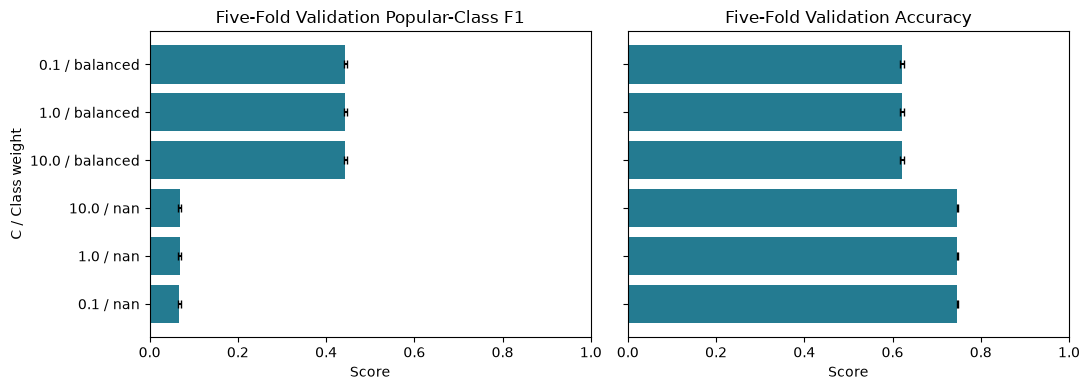

In [17]:
logistic_search = GridSearchCV(
    logistic_pipeline,
    param_grid={
        "classifier__C": [0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring=scoring, refit="f1", cv=cv, n_jobs=1, error_score="raise",
)
logistic_search.fit(X_train, y_train)
show_cv_results(logistic_search, {
    "classifier__C": "C", "classifier__class_weight": "Class weight",
})

### Interpret the Logistic Regression Coefficients

`GridSearchCV` refits the selected pipeline on all training data. We inspect
that fitted model without using the test set. A positive coefficient increases
the estimated log-odds of popularity, holding the other modeled features fixed;
a negative coefficient decreases them.

Because all inputs were standardized, each coefficient represents a one-training-
standard-deviation change, not a one-token change or a direct category switch.
Correlated predictors can affect the coefficients. These are model associations,
not causal effects or guaranteed feature importance rankings.

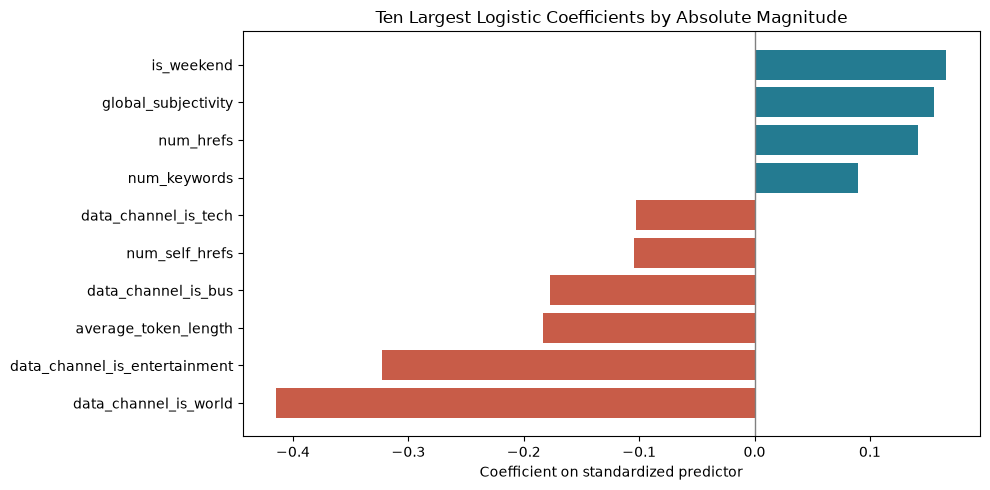

In [18]:
logistic_model = logistic_search.best_estimator_
coefficients = pd.Series(
    logistic_model.named_steps["classifier"].coef_[0], index=feature_columns,
)
largest_coefficients = coefficients.loc[coefficients.abs().nlargest(10).index].sort_values()

plt.figure(figsize=(10, 5))
plt.barh(
    largest_coefficients.index, largest_coefficients.values,
    color=["#247B91" if value > 0 else "#C85C48" for value in largest_coefficients],
)
plt.axvline(0, color="gray", linewidth=1)
plt.title("Ten Largest Logistic Coefficients by Absolute Magnitude")
plt.xlabel("Coefficient on standardized predictor")
plt.tight_layout()
plt.show()
plt.close()

### Evaluate the Selected Logistic Regression on the Test Set

After selecting parameters from training-set cross-validation, we evaluate this
logistic regression pipeline once on the test set. No parameters or thresholds
are changed in response to these scores.

- **Precision:** among predicted-popular articles, how many are actually popular?
- **Recall:** among actually popular articles, how many did the model identify?
- **F1:** the harmonic mean of popular-class precision and recall.
- **ROC-AUC:** how well probabilities rank the classes across thresholds;
  0.5 represents chance ranking.
- **Accuracy:** the fraction of all predictions that are correct, interpreted
  alongside the simple majority-class reference rather than on its own.

The confusion matrix shows error counts at threshold 0.5. Missing popular
articles are false negatives; incorrectly flagging other articles as popular
produces false positives. The ROC curve uses probabilities, not hard labels.

Majority-class reference test accuracy: 0.748


Accuracy     0.625
Precision    0.358
Recall       0.613
F1           0.452
ROC-AUC      0.655
Name: Logistic Regression test score, dtype: float64

              precision    recall  f1-score   support

 Not popular       0.83      0.63      0.72      5931
     Popular       0.36      0.61      0.45      1998

    accuracy                           0.63      7929
   macro avg       0.59      0.62      0.58      7929
weighted avg       0.71      0.63      0.65      7929



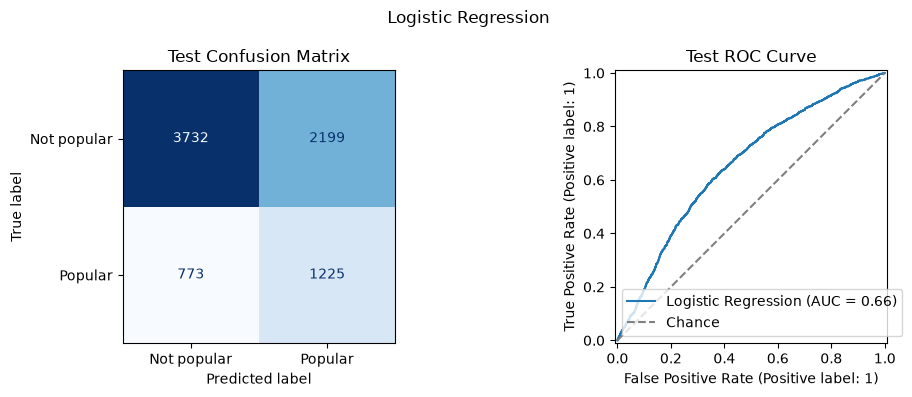

In [19]:
majority_test_accuracy = accuracy_score(y_test, np.full(len(y_test), majority_class))
print(f"Majority-class reference test accuracy: {majority_test_accuracy:.3f}")
logistic_test_scores = evaluate_classifier(logistic_model, X_test, y_test, "Logistic Regression")

### Logistic Regression Findings and Limitations

The output below answers the prediction question using measured results.
Classification performance is not the same as predicting an exact number of
shares. This model uses a linear boundary, and counts remain right-skewed even
after scaling. Popularity can also depend on factors missing from the dataset.
Results from one publisher and historical articles may not generalize to future
articles or other publishers.

In [10]:
print(f"Selected logistic regression: {logistic_search.best_params_}")
print(f"Mean cross-validation F1: {logistic_search.best_score_:.3f}")
print(f"Test F1: {logistic_test_scores['F1']:.3f}; test ROC-AUC: {logistic_test_scores['ROC-AUC']:.3f}")
print(
    f"At threshold 0.5, {logistic_test_scores['Precision']:.1%} of articles flagged as popular "
    f"were popular, and {logistic_test_scores['Recall']:.1%} of all popular articles were identified."
)
print(
    f"Test accuracy was {logistic_test_scores['Accuracy']:.1%}, compared with "
    f"{majority_test_accuracy:.1%} for always predicting the training majority class. "
    "The selected configuration optimizes validation F1, not accuracy."
)

Selected logistic regression: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Mean cross-validation F1: 0.444
Test F1: 0.452; test ROC-AUC: 0.655
At threshold 0.5, 35.8% of articles flagged as popular were popular, and 61.3% of all popular articles were identified.
Test accuracy was 62.5%, compared with 74.8% for always predicting the training majority class. The selected configuration optimizes validation F1, not accuracy.


## 2. Random Forest

Random Forest combines many decision trees trained on bootstrap samples. At each split, every tree considers only a random subset of predictors. This reduces the variance of a single tree and allows the model to learn nonlinear relationships and interactions without requiring feature standardization.

We reuse the **same target, 19 predictors, and train/test split** from the common setup. Random Forest does not require standardized predictors because tree splits depend on ordered values rather than distances between values.

### Preprocessing Pipeline
Median imputation stays inside the pipeline and is fitted separately within each training fold. The imputer handles missing numeric values; the Random Forest then receives the completed feature matrix. The original 0/1 cateogry and weekend flags are treated as numeric binary predictors.


In [6]:
# Add the random forest pipeline and five-fold training-set evaluation.
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1,)),
])

## Five-Fold Cross-Validation and Parameter Selection
We reuse cv and scoring from the other models, so every configuration uses the **same five stratified folds and performance metrics**. Selection uses the mean popular-class F1 score, not test accuracy.

The grid compares two values for max_features, two values for min_samples_leaf, and two class-weight choices: eight configurations and 40 validation fits. max_features controls how many predictors are considered at each split. A larger min_samples_leaf makes trees less complex and can reduce overfitting. Balanced weights give the less frequent popular class greater influence during fitting.

The charts compare validation F1 and accuracy. Read precision and recall alongside F1 when accessing class weighting. Error bars are fold variation, not confidence intervals. The classification threshold remains 0.5 and is not tuned on the test set.

,Maximum features,Minimum leaf size,Class weight,accuracy,precision,recall,f1,roc_auc
0,sqrt,5,balanced,0.679 +/- 0.005,0.391 +/- 0.007,0.495 +/- 0.010,0.437 +/- 0.007,0.674 +/- 0.004
1,9,5,balanced,0.680 +/- 0.005,0.391 +/- 0.006,0.486 +/- 0.009,0.433 +/- 0.006,0.670 +/- 0.004
2,9,1,balanced,0.713 +/- 0.004,0.413 +/- 0.007,0.330 +/- 0.004,0.367 +/- 0.003,0.661 +/- 0.004
3,sqrt,1,balanced,0.719 +/- 0.004,0.423 +/- 0.010,0.308 +/- 0.004,0.356 +/- 0.004,0.665 +/- 0.005
4,9,1,NaN,0.744 +/- 0.003,0.461 +/- 0.024,0.098 +/- 0.004,0.162 +/- 0.007,0.659 +/- 0.006
5,sqrt,1,NaN,0.747 +/- 0.002,0.492 +/- 0.025,0.077 +/- 0.004,0.133 +/- 0.007,0.662 +/- 0.005
6,9,5,NaN,0.749 +/- 0.003,0.510 +/- 0.039,0.072 +/- 0.005,0.126 +/- 0.009,0.668 +/- 0.004
7,sqrt,5,NaN,0.749 +/- 0.002,0.531 +/- 0.045,0.046 +/- 0.004,0.085 +/- 0.008,0.673 +/- 0.004


Selected parameters: {'classifier__class_weight': 'balanced', 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5}
Best mean validation F1: 0.437


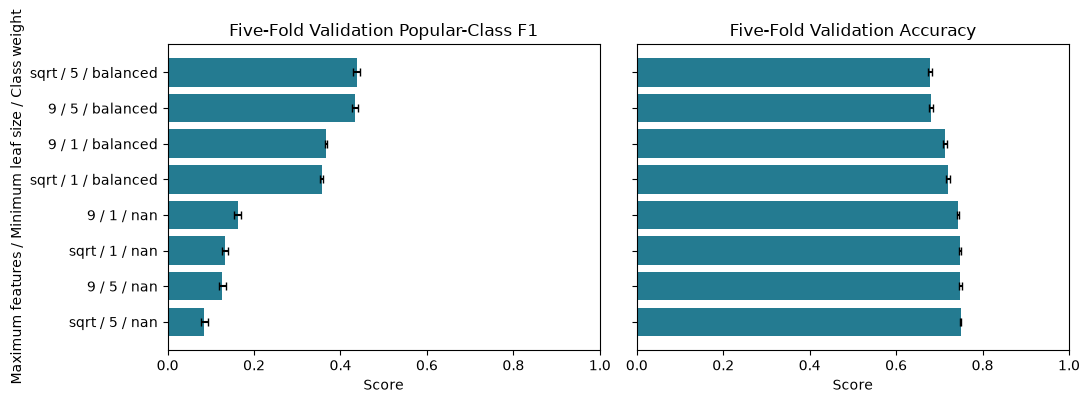

In [13]:
rf_search = GridSearchCV(
    rf_pipeline,
    param_grid={
        "classifier__max_features": ["sqrt", 9],
        "classifier__min_samples_leaf": [1, 5],
        "classifier__class_weight": [None, "balanced"]
    },
    scoring=scoring, refit="f1", cv=cv, n_jobs=1, error_score="raise",
)
rf_search.fit(X_train, y_train)
show_cv_results(rf_search, {
    "classifier__max_features": "Maximum features",
    "classifier__min_samples_leaf": "Minimum leaf size",
    "classifier__class_weight": "Class weight",
})

## Evaluate the Selected Random Forest on the Test Set
GridSearchCV refits the selected pipeline on all training data. We now evaluate that configuration on the same test partition used by logistic regression and histogram gradient boosting. Accuracy, popular-class precision/recall/F1, and probability-based ROC-AUC use the same definitions. The confusion matrix uses threshold 0.5. No hyperparameters or thresholds are changed in response to these test results. 

These are exploratory test results. The eventual model-type decision must use training cross-validation, not whichever test score looks best.

Majority-class reference test accuracy: 0.748


Accuracy     0.685
Precision    0.405
Recall       0.536
F1           0.461
ROC-AUC      0.696
Name: Random Forest test score, dtype: float64

              precision    recall  f1-score   support

 Not popular       0.82      0.74      0.78      5931
     Popular       0.41      0.54      0.46      1998

    accuracy                           0.68      7929
   macro avg       0.61      0.64      0.62      7929
weighted avg       0.72      0.68      0.70      7929



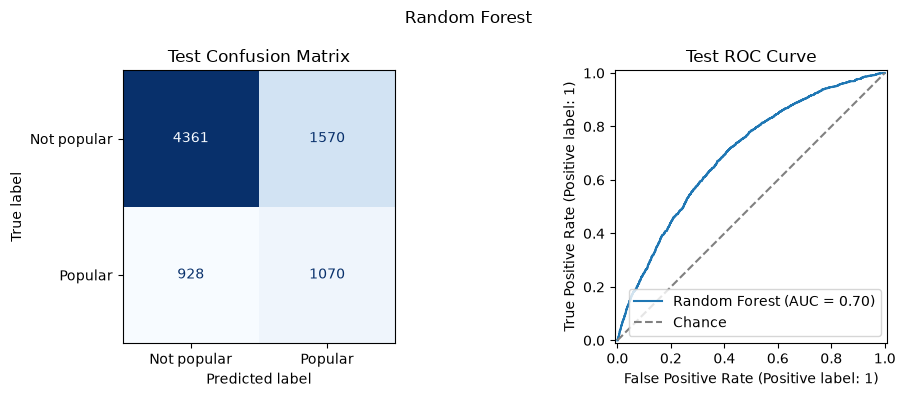

Selected Random Forest parameters: {'classifier__class_weight': 'balanced', 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5}
Mean cross-validation F1: 0.437
Test F1: 0.461; test ROC-AUC: 0.696


In [20]:
rf_model = rf_search.best_estimator_
print(f"Majority-class reference test accuracy: {majority_test_accuracy:.3f}")
rf_test_scores = evaluate_classifier(
    rf_model, X_test, y_test, "Random Forest"
)
print(f"Selected Random Forest parameters: {rf_search.best_params_}")
print(f"Mean cross-validation F1: {rf_search.best_score_:.3f}")
print(
    f"Test F1: {rf_test_scores['F1']:.3f}; "
    f"test ROC-AUC: {rf_test_scores['ROC-AUC']:.3f}"
)

## 3. Histogram Gradient Boosting

Histogram gradient boosting builds decision trees sequentially to reduce the
ensemble's classification loss. Binning numeric values makes split searches
efficient. Unlike logistic regression, it can learn nonlinear relationships and
interactions, such as a media-count pattern differing across categories.

### Preprocessing Pipeline

We reuse the **same target, 19 predictors, and train/test split** from the common
setup. Median imputation stays inside the pipeline and is fitted separately
within each training fold. This model can also handle missing values natively;
we retain imputation to keep the preparation consistent with logistic regression.
Tree splits do not require standardization, so there is no scaler. The original
0/1 category and weekend flags are treated as numeric binary predictors.

In [22]:
hgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.1, max_iter=200, l2_regularization=1.0,
        categorical_features=None, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=10, random_state=RANDOM_STATE,
    )),
])

### Five-Fold Cross-Validation and Parameter Selection

We reuse `cv` and `scoring` from logistic regression, so all configurations use
the **same five stratified folds and performance metrics**. Selection still uses
mean popular-class F1, not test accuracy.

The small grid compares **15 or 31 maximum leaves per tree**, with either no
class weights or balanced weights: four configurations and 20 validation fits.
More leaves allow more complex patterns; balanced weights give the less frequent
popular class greater influence during fitting. L2 regularization is fixed at 1.0.

**Early stopping:** Each fit reserves 10% of its fitting data to monitor loss.
Training can stop before 200 boosting iterations when loss fails to improve
for 10 iterations. This internal validation subset comes from training data,
not the outer cross-validation fold or the final test set. The early-stopping
criterion is loss; the grid-selection criterion is F1. The classification
threshold remains 0.5 and is not tuned on the test set.

The charts compare validation F1 and accuracy. Read precision and recall alongside
F1 when assessing the effect of class weighting. Error bars are fold variation,
not confidence intervals.

,Leaves,Class weight,accuracy,precision,recall,f1,roc_auc
0,15,balanced,0.630 +/- 0.005,0.363 +/- 0.004,0.618 +/- 0.007,0.457 +/- 0.004,0.672 +/- 0.002
1,31,balanced,0.633 +/- 0.003,0.364 +/- 0.002,0.611 +/- 0.003,0.456 +/- 0.002,0.672 +/- 0.003
2,31,NaN,0.750 +/- 0.002,0.543 +/- 0.055,0.049 +/- 0.007,0.089 +/- 0.011,0.671 +/- 0.002
3,15,NaN,0.749 +/- 0.002,0.526 +/- 0.050,0.039 +/- 0.012,0.073 +/- 0.020,0.673 +/- 0.003


Selected parameters: {'classifier__class_weight': 'balanced', 'classifier__max_leaf_nodes': 15}
Best mean validation F1: 0.457


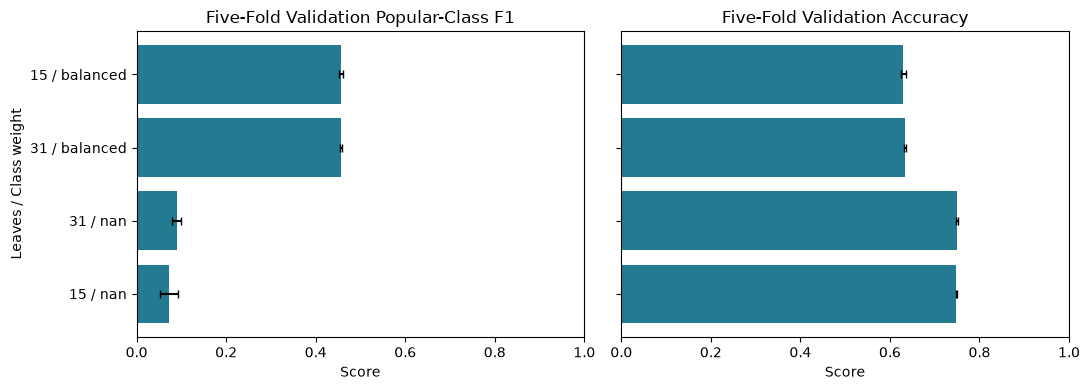

In [23]:
hgb_search = GridSearchCV(
    hgb_pipeline,
    param_grid={
        "classifier__max_leaf_nodes": [15, 31],
        "classifier__class_weight": [None, "balanced"],
    },
    scoring=scoring, refit="f1", cv=cv, n_jobs=1, error_score="raise",
)
hgb_search.fit(X_train, y_train)
show_cv_results(hgb_search, {
    "classifier__max_leaf_nodes": "Leaves", "classifier__class_weight": "Class weight",
})

### Evaluate the Selected Boosting Pipeline on the Test Set

`GridSearchCV` refits the selected pipeline on the training set. With early
stopping enabled, its classifier still reserves an internal validation subset.
The iteration count below describes this refit; it is not chosen from test scores.

We now evaluate the selected configuration on the same test partition used for
logistic regression. Accuracy, popular-class precision/recall/F1, and probability-
based ROC-AUC use the same definitions. The confusion matrix uses threshold 0.5.
No hyperparameters or thresholds are changed in response to these results.

These are exploratory test results: the notebook already evaluated this test
set for logistic regression. The eventual model-type decision must use training
cross-validation, not whichever test score looks best.

Boosting iterations used: 114 of 200
Majority-class reference test accuracy: 0.748


Accuracy     0.636
Precision    0.373
Recall       0.650
F1           0.474
ROC-AUC      0.685
Name: Histogram Gradient Boosting test score, dtype: float64

              precision    recall  f1-score   support

 Not popular       0.84      0.63      0.72      5931
     Popular       0.37      0.65      0.47      1998

    accuracy                           0.64      7929
   macro avg       0.61      0.64      0.60      7929
weighted avg       0.72      0.64      0.66      7929



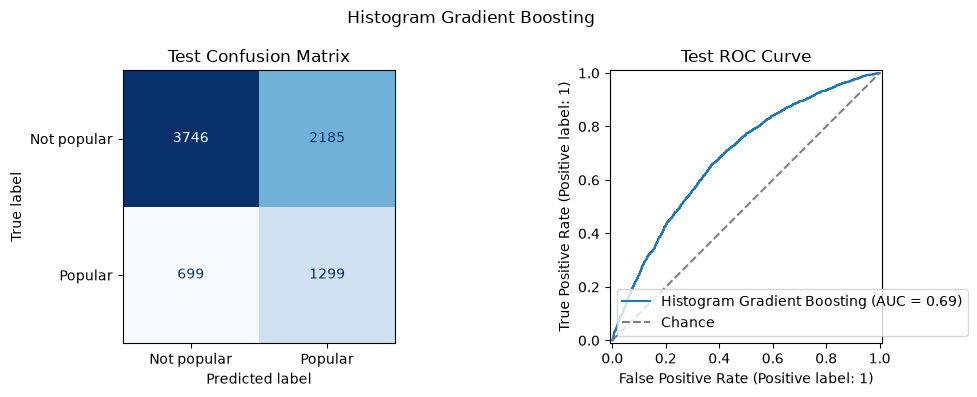

In [24]:
hgb_model = hgb_search.best_estimator_
hgb_classifier = hgb_model.named_steps["classifier"]
print(f"Boosting iterations used: {hgb_classifier.n_iter_} of {hgb_classifier.max_iter}")
print(f"Majority-class reference test accuracy: {majority_test_accuracy:.3f}")
hgb_test_scores = evaluate_classifier(hgb_model, X_test, y_test, "Histogram Gradient Boosting")

### Findings and Comparison with Logistic Regression

The table compares the two **completed** model types using each model's selected
configuration and the same training folds. It includes accuracy as well as our
primary F1 metric. These are tuning/validation scores, not an unbiased external
estimate: the configurations were selected using these cross-validation results.

Random Forest is still empty, so this is **not the final three-model comparison**.
The outcome remains a popularity class, not an exact share-count prediction.
Nonlinear trees can still overfit, class weighting does not guarantee calibrated
probabilities, and the historical single-publisher dataset limits generalization.
No causal interpretation should be attached to the model's predictions.

In [32]:
completed_cv_scores = pd.DataFrame({
    name: {
        "CV F1": search.best_score_,
        "F1 std": search.cv_results_["std_test_f1"][search.best_index_],
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "Accuracy std": search.cv_results_["std_test_accuracy"][search.best_index_],
        "CV ROC-AUC": search.cv_results_["mean_test_roc_auc"][search.best_index_],
    }
    for name, search in {
        "Logistic regression": logistic_search,
        "Random Forest": rf_search,
        "Histogram gradient boosting": hgb_search,
    }.items()
}).T
display(completed_cv_scores.round(3))
print(f"Selected Random Forest parameters: {rf_search.best_params_}")
print(f"Random Forest mean CV F1: {rf_search.best_score_:.3f}")
print(
    f"Random Forest test F1: {rf_test_scores['F1']:.3f}; "
    f"test ROC-AUC {rf_test_scores['ROC-AUC']:.3f}"
)
print(
    f"Random Forest test accuracy was {rf_test_scores['Accuracy']:.1%}, compared with "
    f"{majority_test_accuracy:.1%} for the majority-class reference. "
)
print()
print(f"Selected boosting parameters: {hgb_search.best_params_}")
print(f"Mean cross-validation F1: {hgb_search.best_score_:.3f}")
print(f"Test F1: {hgb_test_scores['F1']:.3f}; test ROC-AUC: {hgb_test_scores['ROC-AUC']:.3f}")
print(
    f"At threshold 0.5, {hgb_test_scores['Precision']:.1%} of articles flagged as popular "
    f"were popular, and {hgb_test_scores['Recall']:.1%} of all popular articles were identified."
)
print(
    f"Test accuracy was {hgb_test_scores['Accuracy']:.1%}, compared with "
    f"{majority_test_accuracy:.1%} for the majority-class reference. "
    "Configuration selection used validation F1, not test accuracy."
)

,CV F1,F1 std,CV accuracy,Accuracy std,CV ROC-AUC
Logistic regression,0.444,0.003,0.622,0.005,0.652
Random Forest,0.437,0.007,0.679,0.005,0.674
Histogram gradient boosting,0.457,0.004,0.630,0.005,0.672


Selected Random Forest parameters: {'classifier__class_weight': 'balanced', 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5}
Random Forest mean CV F1: 0.437
Random Forest test F1: 0.461; test ROC-AUC 0.696
Random Forest test accuracy was 68.5%, compared with 74.8% for the majority-class reference. 

Selected boosting parameters: {'classifier__class_weight': 'balanced', 'classifier__max_leaf_nodes': 15}
Mean cross-validation F1: 0.457
Test F1: 0.474; test ROC-AUC: 0.685
At threshold 0.5, 37.3% of articles flagged as popular were popular, and 65.0% of all popular articles were identified.
Test accuracy was 63.6%, compared with 74.8% for the majority-class reference. Configuration selection used validation F1, not test accuracy.


## 4. Final Three-Model Comparison

**Placeholder.** Complete Random Forest (section 2) before comparing the three model
types on the same training data and folds. Select the overall winner using
cross-validation F1, report accuracy and the other metrics, and then evaluate
that winner on the test set. Test results must not determine the winner.

Logistic regression and histogram gradient boosting are complete, but
multiple configurations do **not** replace the required third model type.

In [16]:
# TODO: Compare the three completed model types and evaluate the selected winner.